In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.ensemble import GradientBoostingRegressor

import warnings
warnings.filterwarnings('ignore')

In [56]:
data=pd.read_csv(r"C:\Users\sivak\Downloads\ML PROJECT NIM (2)\ML PROJECT NIM\google_revenue_prediction_dataset_8000.csv")
data

,Search_Queries_Billion,YouTube_Users_Million,Google_Cloud_Revenue_Million_USD,Advertising_Revenue_Million_USD,Employee_Strength,R&D_Expenditure_Million_USD,AI_Investment_Million_USD,Operating_Expenses_Million_USD,Market_Share_Percent,Economic_Growth_Percent,Digital_Engagement_Index,Total_Revenue_Million_USD
0,9.07,2091.41,30087.72,85000.00,86113,22000.00,5488.47,85000.00,86.92,2.33,40.03,130000.00
1,8.34,1969.14,23246.36,85000.00,65000,24531.89,4000.00,85000.00,86.25,3.17,36.71,130000.00
2,9.25,2055.37,22765.73,103405.23,69521,22000.00,4000.00,85000.00,86.98,2.20,41.88,130000.00
3,10.25,2286.11,29023.42,130948.24,67612,25444.27,4000.00,89527.51,89.27,2.03,38.80,161056.23
4,8.23,2432.62,24165.89,85000.00,77782,23505.05,4000.00,85000.00,87.52,2.80,42.20,130000.00
...,...,...,...,...,...,...,...,...,...,...,...,...
7995,13.50,2971.93,81957.01,250000.00,187225,51265.65,35956.34,229910.78,92.70,4.64,69.87,331720.50
7996,11.87,3159.21,72903.95,250000.00,174235,49356.46,36985.82,218579.90,89.64,3.27,66.51,306297.09
7997,10.54,2776.29,65232.19,234810.52,172372,51837.37,33608.84,207731.39,91.73,3.23,59.52,295441.44
7998,13.40,3020.13,77235.15,250000.00,181666,52088.96,31370.15,225371.73,95.30,3.70,71.77,327448.91


## Exploratory Data Analysis(EDA)

In [9]:
data.head()

,Search_Queries_Billion,YouTube_Users_Million,Google_Cloud_Revenue_Million_USD,Advertising_Revenue_Million_USD,Employee_Strength,R&D_Expenditure_Million_USD,AI_Investment_Million_USD,Operating_Expenses_Million_USD,Market_Share_Percent,Economic_Growth_Percent,Digital_Engagement_Index,Total_Revenue_Million_USD
0,9.07,2091.41,30087.72,85000.00,86113,22000.00,5488.47,85000.00,86.92,2.33,40.03,130000.00
1,8.34,1969.14,23246.36,85000.00,65000,24531.89,4000.00,85000.00,86.25,3.17,36.71,130000.00
2,9.25,2055.37,22765.73,103405.23,69521,22000.00,4000.00,85000.00,86.98,2.20,41.88,130000.00
3,10.25,2286.11,29023.42,130948.24,67612,25444.27,4000.00,89527.51,89.27,2.03,38.80,161056.23
4,8.23,2432.62,24165.89,85000.00,77782,23505.05,4000.00,85000.00,87.52,2.80,42.20,130000.00


In [10]:
data.tail()

,Search_Queries_Billion,YouTube_Users_Million,Google_Cloud_Revenue_Million_USD,Advertising_Revenue_Million_USD,Employee_Strength,R&D_Expenditure_Million_USD,AI_Investment_Million_USD,Operating_Expenses_Million_USD,Market_Share_Percent,Economic_Growth_Percent,Digital_Engagement_Index,Total_Revenue_Million_USD
7995,13.50,2971.93,81957.01,250000.00,187225,51265.65,35956.34,229910.78,92.70,4.64,69.87,331720.50
7996,11.87,3159.21,72903.95,250000.00,174235,49356.46,36985.82,218579.90,89.64,3.27,66.51,306297.09
7997,10.54,2776.29,65232.19,234810.52,172372,51837.37,33608.84,207731.39,91.73,3.23,59.52,295441.44
7998,13.40,3020.13,77235.15,250000.00,181666,52088.96,31370.15,225371.73,95.30,3.70,71.77,327448.91
7999,13.50,2996.95,79153.74,250000.00,178991,47193.79,34808.10,230000.00,94.24,2.71,76.13,312094.86


In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Search_Queries_Billion            8000 non-null   float64
 1   YouTube_Users_Million             8000 non-null   float64
 2   Google_Cloud_Revenue_Million_USD  8000 non-null   float64
 3   Advertising_Revenue_Million_USD   8000 non-null   float64
 4   Employee_Strength                 8000 non-null   int64  
 5   R&D_Expenditure_Million_USD       8000 non-null   float64
 6   AI_Investment_Million_USD         8000 non-null   float64
 7   Operating_Expenses_Million_USD    8000 non-null   float64
 8   Market_Share_Percent              8000 non-null   float64
 9   Economic_Growth_Percent           8000 non-null   float64
 10  Digital_Engagement_Index          8000 non-null   float64
 11  Total_Revenue_Million_USD         8000 non-null   float64
dtypes: flo

In [12]:
data.describe()

,Search_Queries_Billion,YouTube_Users_Million,Google_Cloud_Revenue_Million_USD,Advertising_Revenue_Million_USD,Employee_Strength,R&D_Expenditure_Million_USD,AI_Investment_Million_USD,Operating_Expenses_Million_USD,Market_Share_Percent,Economic_Growth_Percent,Digital_Engagement_Index,Total_Revenue_Million_USD
count,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.00000,8000.000000,8000.000000,8000.000000,8000.00000,8000.00000,8000.000000
mean,9.99244,2475.033692,46050.416392,162942.432645,122436.767375,37155.63689,18608.763405,145941.150671,89.241641,3.35694,50.00922,209956.377211
std,1.42433,335.474094,14211.731393,49922.485479,28467.699870,9751.94307,8971.598748,41785.838459,2.199906,1.02607,10.37889,57712.513271
min,5.00000,1300.000000,18000.000000,85000.000000,65000.000000,22000.00000,4000.000000,85000.000000,82.000000,-1.15000,20.00000,130000.000000
25%,9.00000,2238.560000,34898.087500,120553.067500,99046.750000,28778.04250,10996.590000,108728.097500,87.710000,2.65000,42.54750,157919.730000
50%,10.00000,2473.120000,45852.360000,161995.940000,122198.500000,37026.25000,18474.275000,145284.720000,89.230000,3.36000,50.04000,207228.855000
75%,10.97000,2710.795000,56948.335000,203871.442500,145125.000000,45164.29000,25996.535000,181444.647500,90.770000,4.06000,57.36250,257016.172500
max,13.50000,3200.000000,84602.670000,250000.000000,190000.000000,63394.20000,40000.000000,230000.000000,96.550000,6.00000,82.85000,339642.660000


In [13]:
data.duplicated().any()

np.False_

In [14]:
data.isnull().sum()

Search_Queries_Billion              0
YouTube_Users_Million               0
Google_Cloud_Revenue_Million_USD    0
Advertising_Revenue_Million_USD     0
Employee_Strength                   0
R&D_Expenditure_Million_USD         0
AI_Investment_Million_USD           0
Operating_Expenses_Million_USD      0
Market_Share_Percent                0
Economic_Growth_Percent             0
Digital_Engagement_Index            0
Total_Revenue_Million_USD           0
dtype: int64

## Visualizing Using Matplotlib

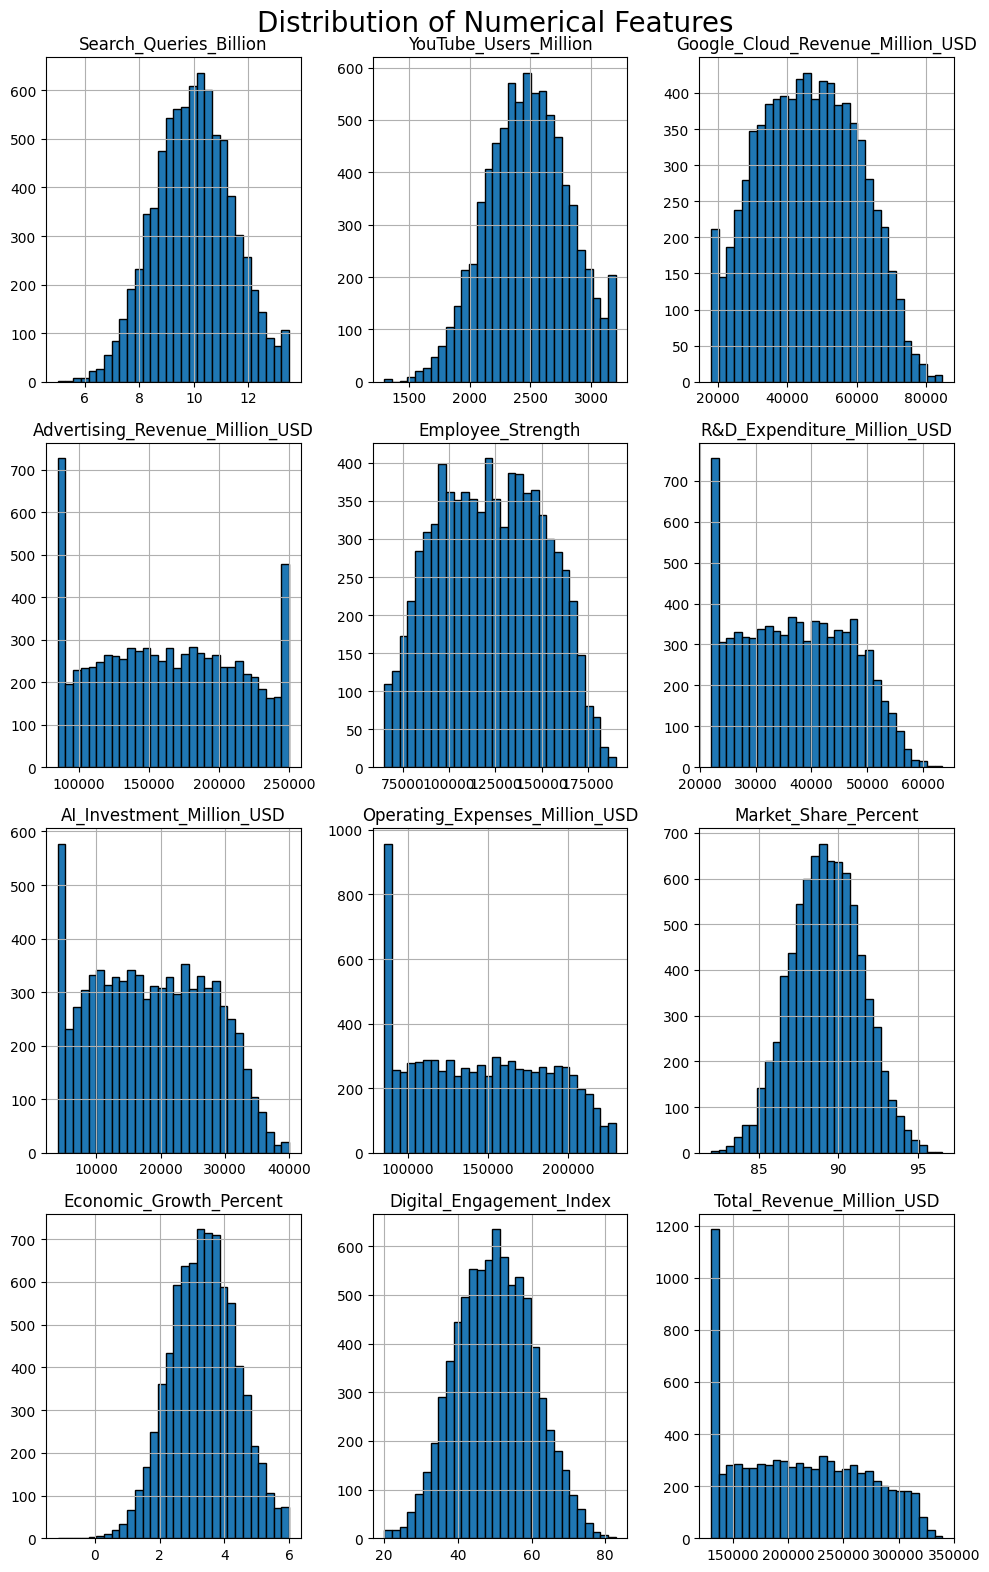

In [15]:
#Histograms

data.hist(
    figsize=(10, 16),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=20
)

plt.tight_layout()
plt.show()

In [16]:
data.dtypes

Search_Queries_Billion              float64
YouTube_Users_Million               float64
Google_Cloud_Revenue_Million_USD    float64
Advertising_Revenue_Million_USD     float64
Employee_Strength                     int64
R&D_Expenditure_Million_USD         float64
AI_Investment_Million_USD           float64
Operating_Expenses_Million_USD      float64
Market_Share_Percent                float64
Economic_Growth_Percent             float64
Digital_Engagement_Index            float64
Total_Revenue_Million_USD           float64
dtype: object

In [17]:
# Correlation with Target

target_column = "Total_Revenue_Million_USD"

target_correlations = (
    data.corr()[target_column]
    .sort_values(ascending=False)
)

print("\nCorrelation with target:")
print(target_correlations)


Correlation with target:
Total_Revenue_Million_USD           1.000000
Advertising_Revenue_Million_USD     0.987336
Operating_Expenses_Million_USD      0.942318
Google_Cloud_Revenue_Million_USD    0.940120
R&D_Expenditure_Million_USD         0.909655
Employee_Strength                   0.898316
AI_Investment_Million_USD           0.869406
Digital_Engagement_Index            0.827949
Search_Queries_Billion              0.820302
Market_Share_Percent                0.795252
YouTube_Users_Million               0.658016
Economic_Growth_Percent             0.209050
Name: Total_Revenue_Million_USD, dtype: float64


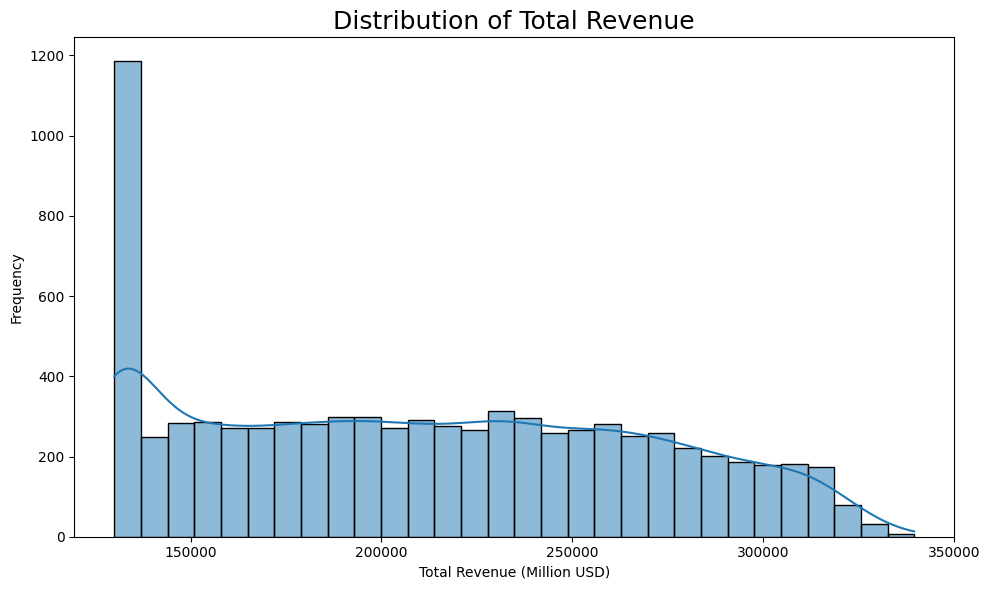

In [18]:
# Target Distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    data[target_column],
    kde=True,
    bins=30
)

plt.title(
    "Distribution of Total Revenue",
    fontsize=18
)

plt.xlabel("Total Revenue (Million USD)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

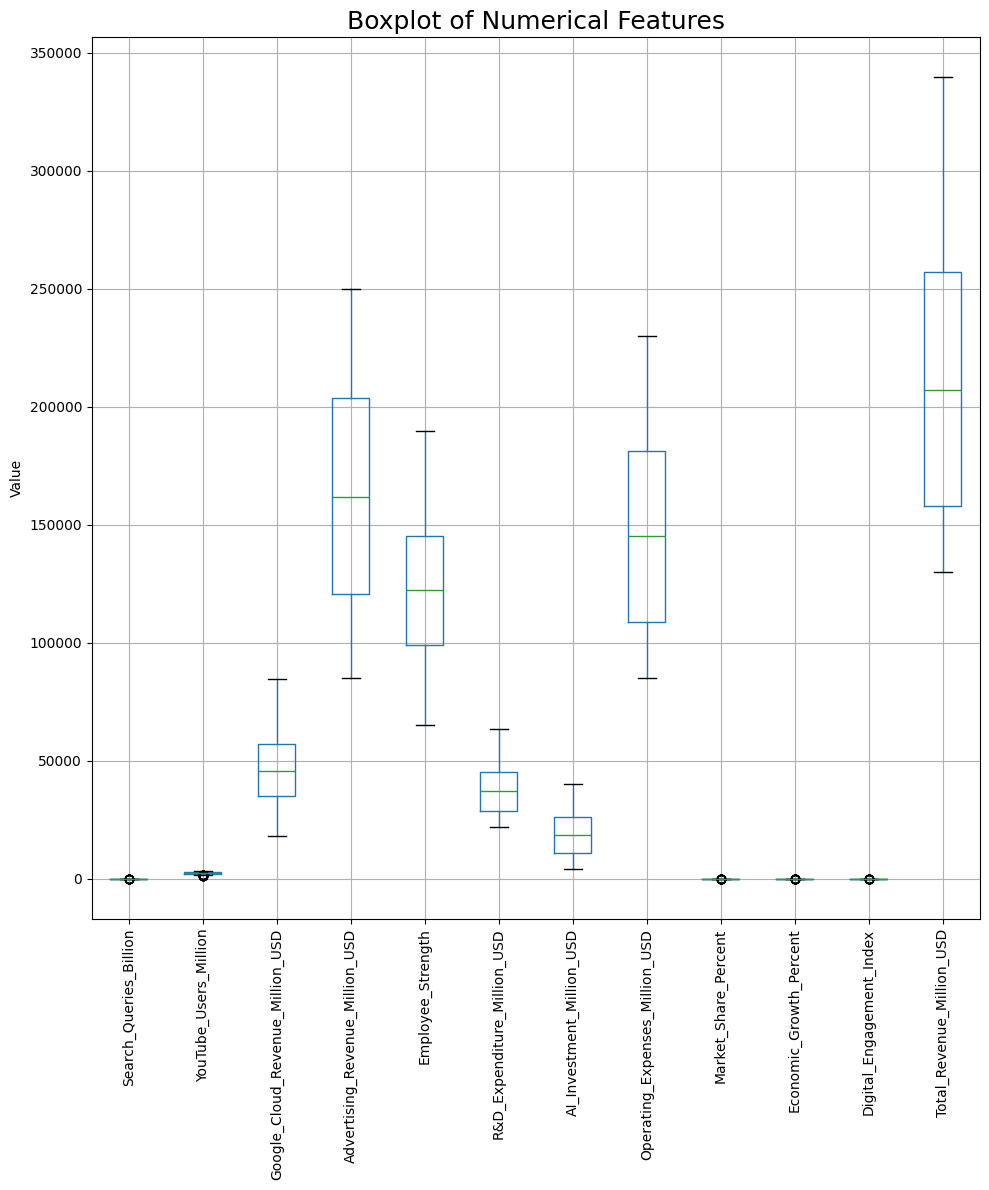

In [19]:
 #Boxplots

plt.figure(figsize=(10, 12))

data.boxplot(rot=90)

plt.title(
    "Boxplot of Numerical Features",
    fontsize=18
)

plt.ylabel("Value")

plt.tight_layout()
plt.show()


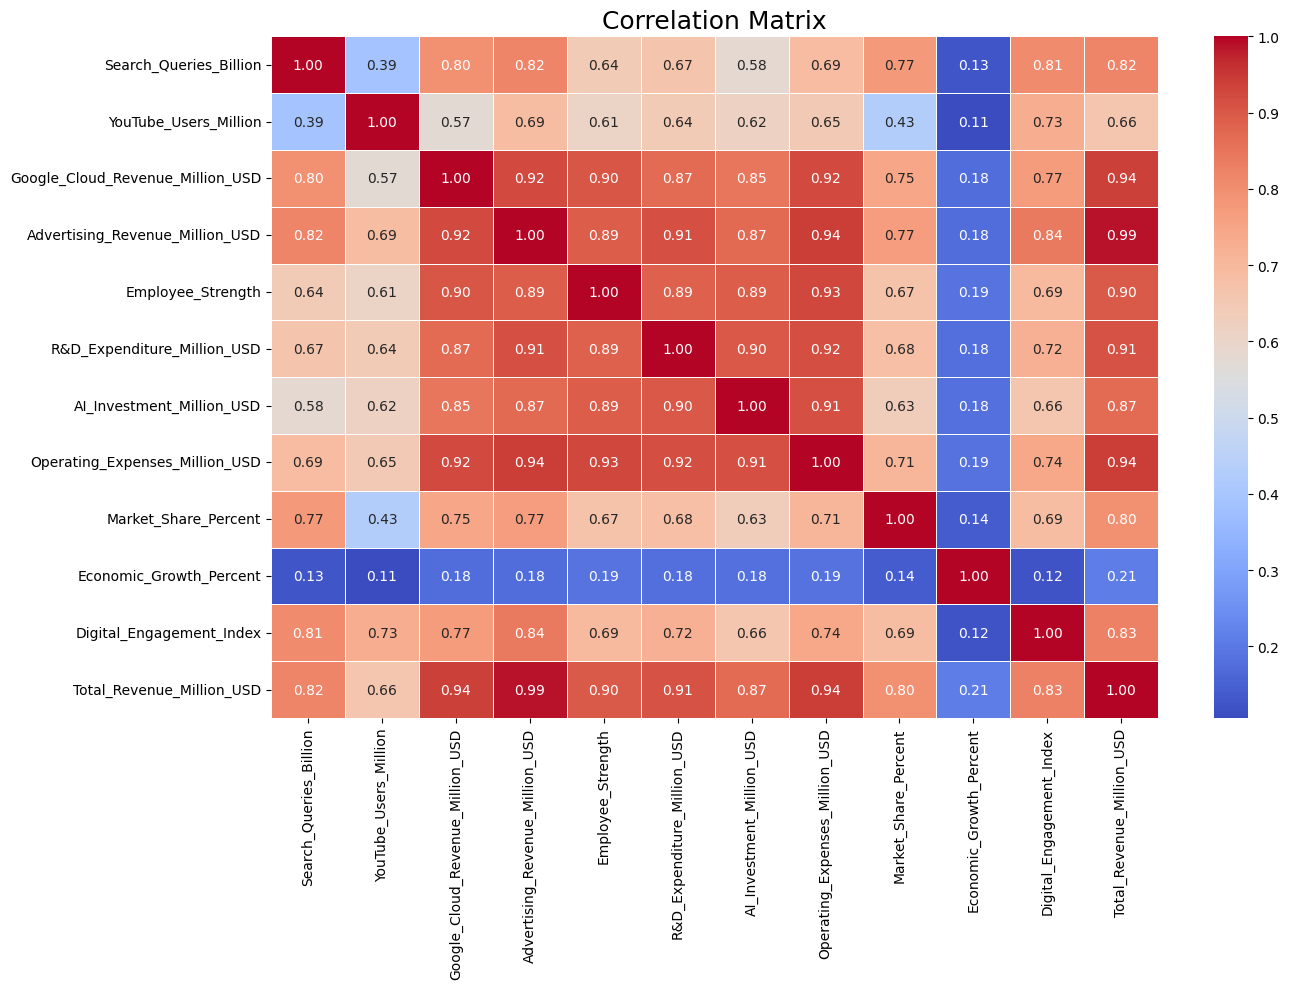

In [20]:
# Correlation Matrix

correlation_matrix = data.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title(
    "Correlation Matrix",
    fontsize=18
)

plt.tight_layout()
plt.show()

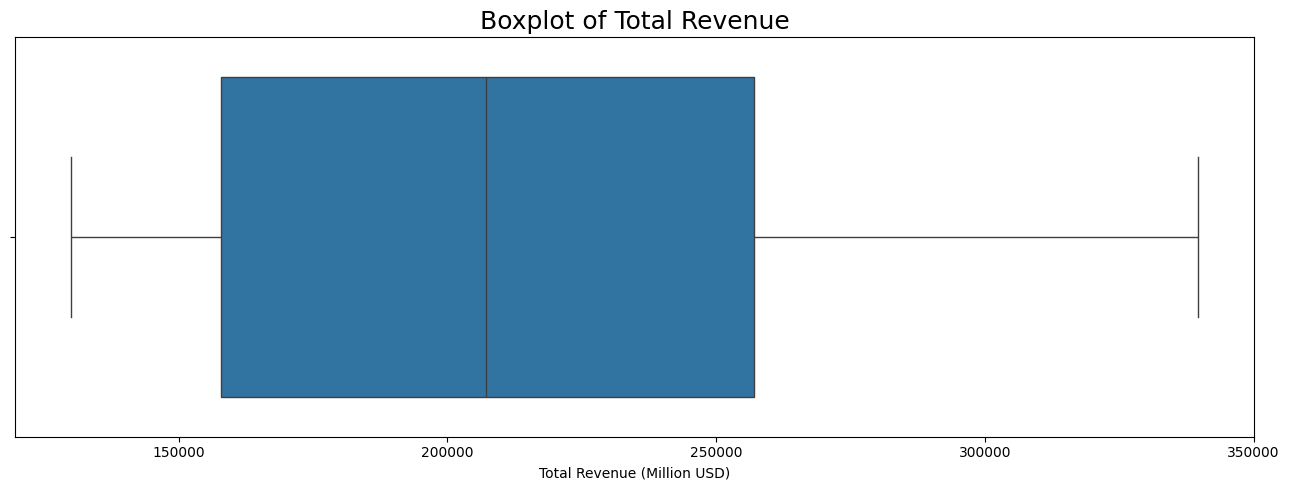

In [21]:
#  Target Boxplot

plt.figure(figsize=(13, 5))

sns.boxplot(
    x=data[target_column]
)

plt.title(
    "Boxplot of Total Revenue",
    fontsize=18
)

plt.xlabel("Total Revenue (Million USD)")

plt.tight_layout()
plt.show()

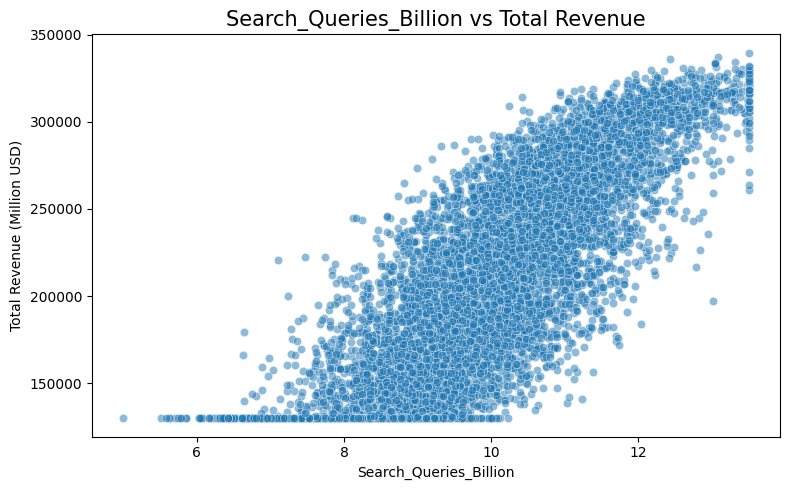

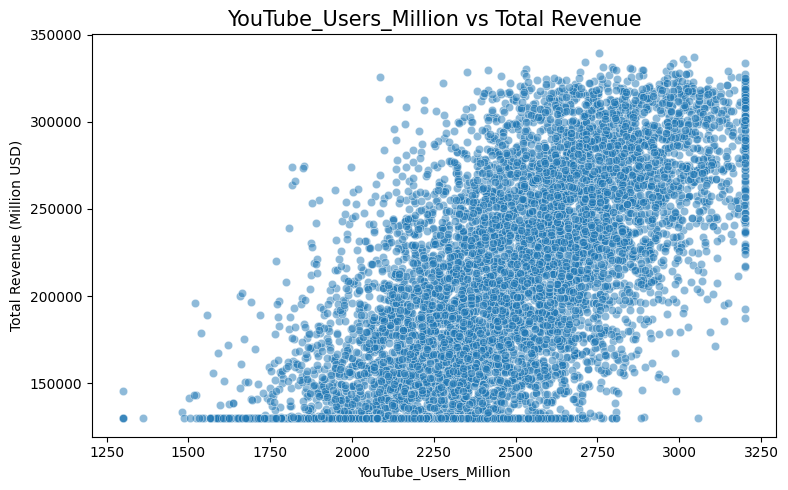

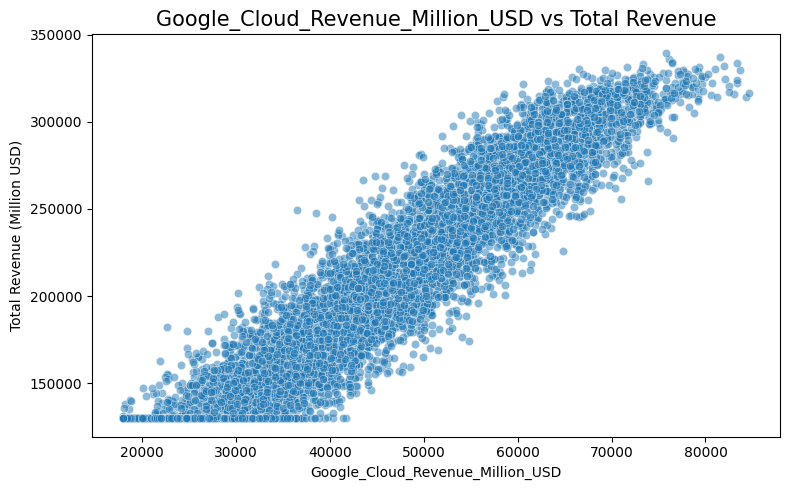

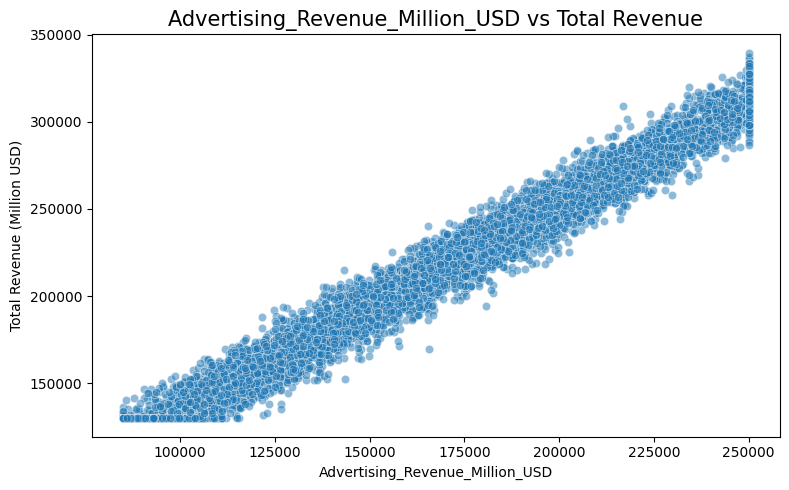

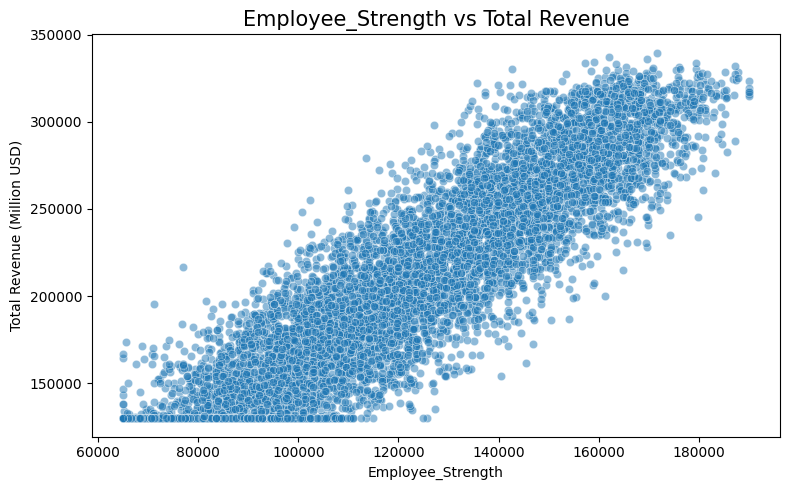

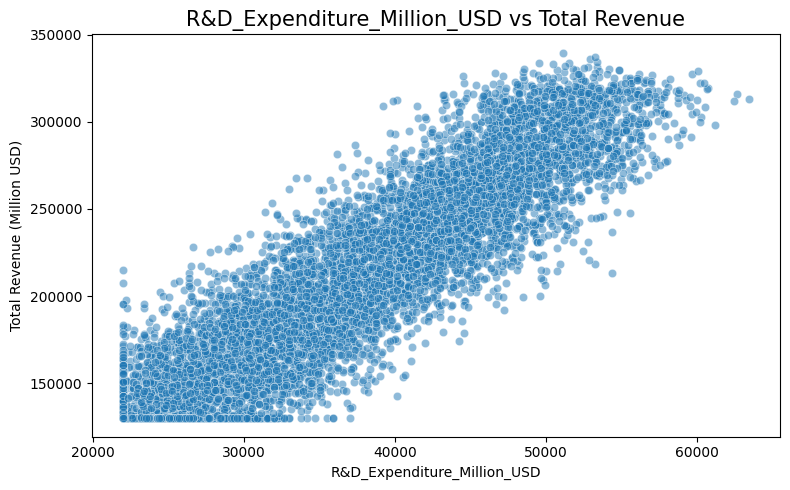

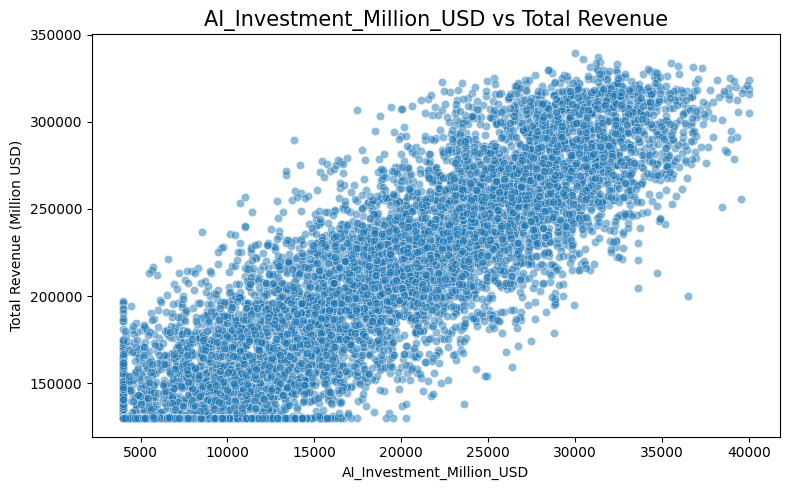

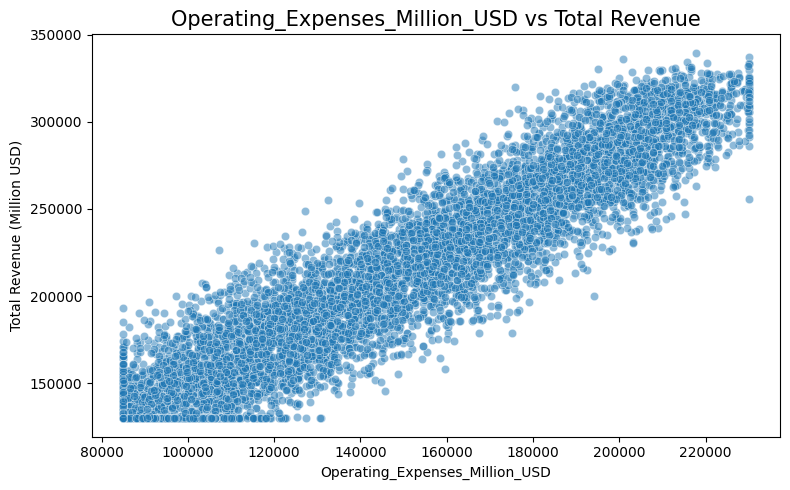

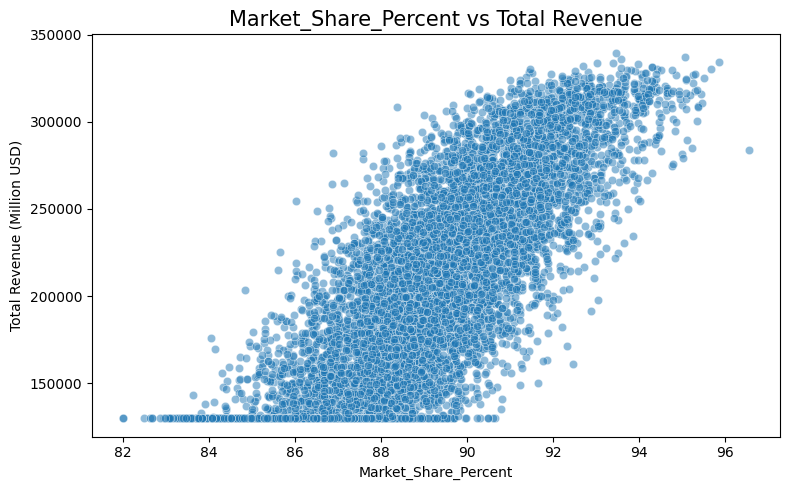

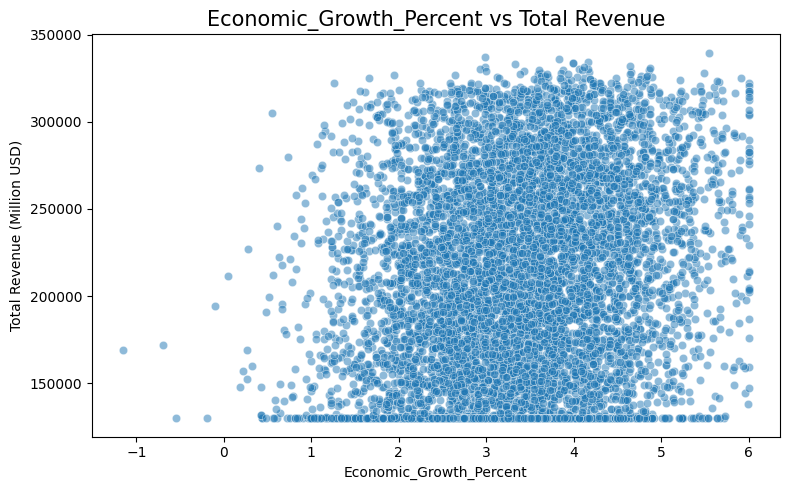

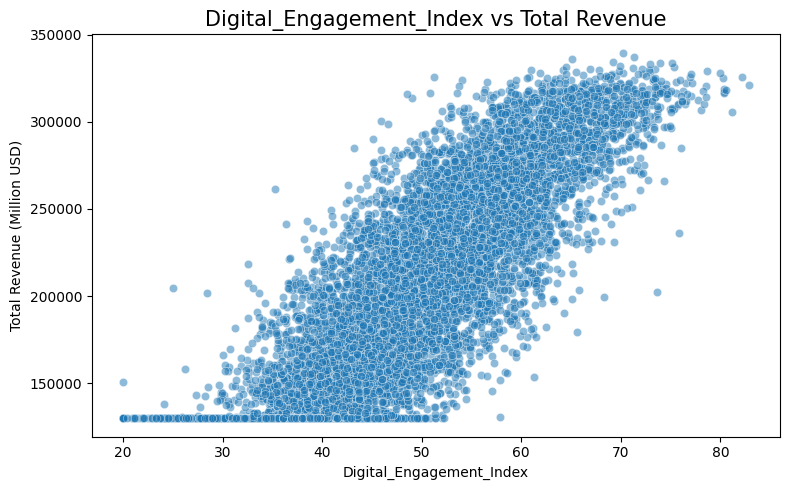

In [22]:
# Feature vs Target Scatter Plots

features_for_plot = [
    "Search_Queries_Billion",
    "YouTube_Users_Million",
    "Google_Cloud_Revenue_Million_USD",
    "Advertising_Revenue_Million_USD",
    "Employee_Strength",
    "R&D_Expenditure_Million_USD",
    "AI_Investment_Million_USD",
    "Operating_Expenses_Million_USD",
    "Market_Share_Percent",
    "Economic_Growth_Percent",
    "Digital_Engagement_Index"
]

for feature in features_for_plot:

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=data,
        x=feature,
        y=target_column,
        alpha=0.5
    )

    plt.title(
        f"{feature} vs Total Revenue",
        fontsize=15
    )

    plt.xlabel(feature)
    plt.ylabel("Total Revenue (Million USD)")

    plt.tight_layout()
    plt.show()

In [23]:
data.dtypes

Search_Queries_Billion              float64
YouTube_Users_Million               float64
Google_Cloud_Revenue_Million_USD    float64
Advertising_Revenue_Million_USD     float64
Employee_Strength                     int64
R&D_Expenditure_Million_USD         float64
AI_Investment_Million_USD           float64
Operating_Expenses_Million_USD      float64
Market_Share_Percent                float64
Economic_Growth_Percent             float64
Digital_Engagement_Index            float64
Total_Revenue_Million_USD           float64
dtype: object

In [24]:
# TRAIN-TEST SPLIT

x=data.drop(['Total_Revenue_Million_USD'],axis=1)
y=data['Total_Revenue_Million_USD']

In [25]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.3,random_state=1)

# Model Fitting

# Linear Regression

In [26]:
model1=LinearRegression()
model1.fit(xtrain,ytrain)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [27]:
model1.predict(xtest)
lineartrain=model1.score(xtrain,ytrain)*100
lineartrain

98.40192415885704

In [28]:
lineartest=model1.score(xtest,ytest)*100
lineartest

98.3141266764381

In [29]:
model2=DecisionTreeRegressor()
model2.fit(xtrain,ytrain)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [30]:
model2.predict(xtest)
Treetrain=model2.score(xtrain,ytrain)*100
Treetrain

100.0

In [31]:
treetest=model2.score(xtest,ytest)*100
treetest

97.48163758609655

In [32]:
model3=RandomForestRegressor(n_estimators=50,random_state=1)
model3.fit(xtrain,ytrain)

,n_estimators,50
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [33]:
model3.predict(xtest)

array([216296.5254, 210043.567 , 227477.7366, ..., 202458.841 ,
       262317.8646, 145858.3288], shape=(2400,))

In [34]:
foresttrain=model3.score(xtrain,ytrain)*100
foresttrain

99.8076460071191

In [35]:
foresttest=model3.score(xtest,ytest)*100
foresttest

98.67017465463407

In [36]:
model4=KNeighborsRegressor(n_neighbors=9)
model4.fit(xtrain,ytrain)

,n_neighbors,9
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [37]:
model4.predict(xtest)

array([204601.15333333, 214134.34888889, 217953.02222222, ...,
       201641.91111111, 262396.50444444, 148533.82333333], shape=(2400,))

In [38]:
neighbortrain=model4.score(xtrain,ytrain)*100
neighbortrain

98.48327810074309

In [39]:
neighbortest=model4.score(xtest,ytest)*100
neighbortest

98.07779276505333

In [40]:
model5=AdaBoostRegressor(n_estimators=50,random_state=1)
model5.fit(xtrain,ytrain)

,estimator,None
,n_estimators,50
,learning_rate,1.0
,loss,'linear'
,random_state,1


In [41]:
model5.predict(xtest)

array([207313.84563481, 214851.78740657, 224845.2578071 , ...,
       201946.83755289, 262527.75529274, 145755.51475719], shape=(2400,))

In [42]:
Adaboosttrain=model5.score(xtrain,ytrain)*100
Adaboosttrain

97.98933249170602

In [43]:
Adaboosttest=model5.score(xtest,ytest)*100
Adaboosttest

97.82146578160908

In [44]:
model6=GradientBoostingRegressor(n_estimators=50,random_state=1)
model6.fit(xtrain,ytrain)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,50
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [45]:
model6.predict(xtest)

array([210534.68401116, 214450.35453838, 224167.43873474, ...,
       200685.0107832 , 264196.50427564, 145013.99402205], shape=(2400,))

In [46]:
gradienttrain=model6.score(xtrain,ytrain)*100
gradienttrain

98.93412906539471

In [47]:
gradienttest=model6.score(xtest,ytest)*100
gradienttest

98.75047623077829

## Representing Models Training and Testing Score Graphically


In [48]:
score=pd.DataFrame({'Model':['LinearRegression','DecisionTreeRegression','RandomForestRegressor',
                           'KNeighborRegressor','AdaBoostRegressor','GradientBoostRegressor'],
                    'TrainingScores': [lineartrain,Treetrain,foresttrain,neighbortrain,Adaboosttrain,gradienttrain],
                    'TestingScore': [lineartest,treetest,foresttest,neighbortest,Adaboosttest,gradienttest]})
score

,Model,TrainingScores,TestingScore
0,LinearRegression,98.401924,98.314127
1,DecisionTreeRegression,100.000000,97.481638
2,RandomForestRegressor,99.807646,98.670175
3,KNeighborRegressor,98.483278,98.077793
4,AdaBoostRegressor,97.989332,97.821466
5,GradientBoostRegressor,98.934129,98.750476


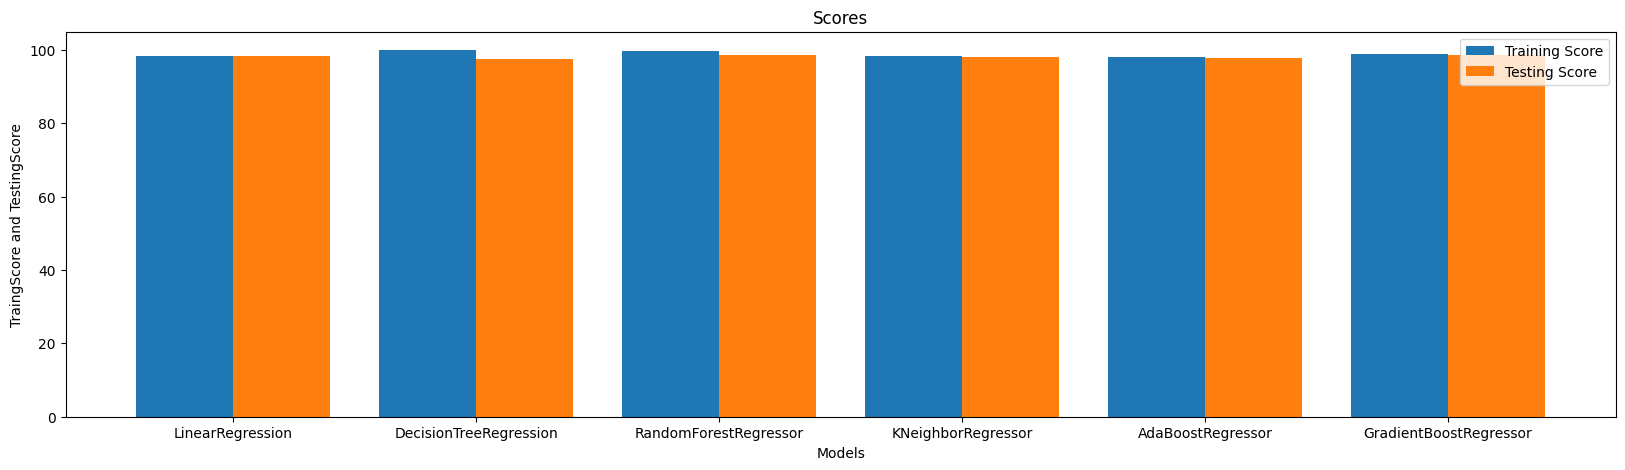

In [49]:
x=score.Model
y=score.TrainingScores
z=score.TestingScore
width=0.4
x_indices = np.arange(len(x))
plt.figure(figsize=(20,5))
plt.bar(x_indices - width / 2, y, width=width, label='Training Score')
plt.bar(x_indices + width / 2, z, width=width, label='Testing Score')
plt.xticks(x_indices, x)
plt.xlabel('Models')
plt.ylabel('TraingScore and TestingScore')
plt.title("Scores")
plt.legend()
plt.show()

In [50]:
models = {

    "Linear Regression":
        LinearRegression(),

    "Decision Tree":
        DecisionTreeRegressor(
            max_depth=10,
            random_state=42
        ),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            random_state=42,
            n_jobs=-1
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ),

    "KNN":
        KNeighborsRegressor(
            n_neighbors=5
        )
}

In [51]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

In [52]:

results = []

predictions = {}

for name, model in models.items():

    # Train model
    model.fit(xtrain,ytrain)

    # Prediction
    prediction = model.predict(xtest)

    # Save prediction
    predictions[name] = prediction

    # Evaluation
    mae = mean_absolute_error(
        ytest,
        prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            ytest,
            prediction
        )
    )

    r2 = r2_score(
        ytest,
        prediction
    )*100

    results.append([
        name,
        mae,
        rmse,
        r2
    ])

In [53]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "MAE",
        "RMSE",
        "R2 Score"
    ]
)

print("\n========== MODEL COMPARISON ==========")

print(results_df)


========== MODEL COMPARISON ==========
               Model          MAE         RMSE   R2 Score
0  Linear Regression  5921.029688  7441.913709  98.314127
1      Decision Tree  6312.080031  8451.108034  97.825883
2      Random Forest  4976.085041  6577.208398  98.683142
3  Gradient Boosting  4888.619030  6323.190572  98.782895
4                KNN  6245.116150  8198.877334  97.953723


In [54]:
best_index = results_df["R2 Score"].idxmax()

best_model_name = results_df.loc[
    best_index,
    "Model"
]

best_prediction = predictions[
    best_model_name
]

print("\n========== BEST MODEL ==========")

print("Best Model:", best_model_name)

print(
    "Best R2 Score:",
    results_df.loc[
        best_index,
        "R2 Score"
    ]
)


========== BEST MODEL ==========
Best Model: Gradient Boosting
Best R2 Score: 98.78289451136149


In [55]:
import joblib

joblib.dump(model, "best_model.pkl")

['best_model.pkl']